# Weights for uniformity: from Gerchberg-Saxton to a uniform array

**Question:** How do weights turn Gerchberg-Saxton into a uniform trap array, how fast does weighted Gerchberg-Saxton get there, and what does the adaptive additive variant buy on the way?

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic
- **Reading time:** about 50 minutes

## Objectives

The previous notebook ended with a loop that is efficient and not uniform: on nine traps the spread of the powers stalled near 7 percent. Experiments want traps within a few percent of each other, because the trap depth follows the power. This notebook adds the one change that fixes it, a weight per trap that remembers how dim the trap has been, and measures what it does on the 100 traps of C12. You will read the weights of the very first update, run plain, adaptive additive and weighted Gerchberg-Saxton from the same start, count the iterations that each needs to reach 5, 2 and 1 percent of spread, sweep the strength of the adaptive term, and check how much the speed depends on the random start.

## Setup

The notebook environment is pinned in `notebooks/requirements.txt` and built with `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows). The packages this notebook uses, with their exact pins:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot publishes no package of its own: its methods live in `data-pipeline/pipeline/` and the notebook imports them by their path. The next cell imports the tools, prints their versions and puts the pipeline on the path.

In [1]:
# the tools and their versions, then the pipeline's modules by path
import importlib.metadata as md
import sys
import warnings
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.build import setup_of, target_of
from pipeline.io.contract import read_cases
from pipeline.model.holo.core import forward, metrics
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.traps import TrapSet
from pipeline.model.holo.core.types import Budget, Target
from pipeline.model.holo.methods.baseline import m02_random_superposition, m04_gs, m05_gaa, m06_gsw

for name in ("numpy", "matplotlib"):
    print(name, md.version(name))


def first_below(history, percent):
    """The first iteration whose relative spread is below ``percent``, or None."""
    return next((h["iteration"] for h in history if h["rel_std"] < percent), None)

numpy 2.4.6
matplotlib 3.11.2


## Data

- Owner: this repository, https://github.com/fsantibanezleal/CEFOP_DinHot.
- Licence class: synthetic case written by the product, no third-party dataset, covered by the repository licence.
- File read: `data/examples/cases.json`, case C12, 100 traps on the 256 by 256 pixel SLM, the case seed 20261028 and three seeds counted up from it.

In [2]:
# case C12: the 10 x 10 array with a 30 iteration budget; every run starts from the same random-phase hologram
records = {rec["case_id"]: rec for rec in read_cases(ROOT / "data" / "examples" / "cases.json")}
rec = records["C12_calibration"]
setup = setup_of(rec)
target = target_of(rec)
traps = target.traps
seed = rec["seed"]
phi0 = m02_random_superposition.run(setup, target, budget=Budget(1), rng=Rng(seed)).phi
print(f"{len(traps)} traps, iterations in the budget: {rec['budget']['iterations']}, seed {seed}")

100 traps, iterations in the budget: 30, seed 20261028


## Method

Write $r_m = |V_m|/a_m$ for the amplitude of trap $m$ relative to its target amplitude. Plain Gerchberg-Saxton asks the traps for $c_m = a_m V_m/|V_m|$, whatever $r_m$ is. Weighted Gerchberg-Saxton (M06) keeps a weight per trap, updated before each iteration by $w_m \leftarrow w_m \langle r\rangle/r_m$, and asks for $c_m = w_m V_m/|V_m|$: a trap that came out dim gets a larger weight and is asked for more next time, and a bright one is asked for less (Di Leonardo et al. 2007, Eq. 18, https://doi.org/10.1364/OE.15.001913). The adaptive additive variant (M05) instead rescales each request by $(1-\alpha) + \alpha/r_m$, with no memory (the same paper, Eqs. 15 and 16; the bracket is a reconstruction that the product marks as unverified, and it depends on the absolute scale of $|V_m|$, so by default the amplitudes are expressed in units of their mean). With $\alpha = 0$ it is plain Gerchberg-Saxton. The steps below measure the first weights, then the three methods, then the strength $\alpha$, then the seeds.

The weights of the very first update can be computed without any iteration. From the random-phase start, read the amplitudes $|V_m|$ of the 100 traps with the forward model and form $w = \langle r\rangle/r$. If the weights do what the text says, they must be larger where the trap is dim, which is a negative correlation with the trap power. The cell prints the range of the weights and that correlation.

In [3]:
# the weight of the first update, w = mean(r) / r with r = |V|, from the traps' amplitudes at the start
v0 = forward.point_trap_fields(phi0, setup, traps)
r0 = np.abs(v0)
w1 = r0.mean() / r0
power0 = metrics.trap_intensities(v0)
print(f"weights of the first update, range: {w1.min():.3f} to {w1.max():.3f}")
print(f"correlation of the weight with the trap power: {np.corrcoef(w1, power0)[0, 1]:.3f}")

weights of the first update, range: 0.671 to 2.018
correlation of the weight with the trap power: -0.914


Now the three methods from the same start for 60 iterations, which is twice the budget of the case so that the slow methods show their trend. The cell prints the relative spread at iterations 1, 10, 30 and 60.

In [4]:
# plain GS, adaptive-additive GS (alpha 0.5) and weighted GS, 60 iterations from the same start
runs = {}
for name, method in (("M04", m04_gs), ("M05", m05_gaa), ("M06", m06_gsw)):
    runs[name] = method.run(setup, target, budget=Budget(60), rng=Rng(seed), init=phi0)
for name, res in runs.items():
    sigma = [h["rel_std"] for h in res.history]
    at = [sigma[k - 1] for k in (1, 10, 30, 60)]
    print(f"{name}: sigma at iteration 1, 10, 30, 60 = " + ", ".join(f"{x:.2f}" for x in at) + " %")

M04: sigma at iteration 1, 10, 30, 60 = 28.55, 21.55, 19.97, 16.89 %
M05: sigma at iteration 1, 10, 30, 60 = 20.98, 15.02, 11.81, 11.34 %
M06: sigma at iteration 1, 10, 30, 60 = 28.55, 4.57, 1.02, 0.16 %


The spread at fixed iterations hides how long each method takes to be good enough. The cell finds, for each method, the first iteration at which the spread is under 5, 2 and 1 percent (None when it never gets there in 60 iterations), and prints the efficiency and uniformity of iteration 30.

In [5]:
# how many iterations each method needs to bring the spread under 5, 2 and 1 percent
for name, res in runs.items():
    steps = [first_below(res.history, p) for p in (5, 2, 1)]
    h30 = res.history[29]
    print(f"{name}: iterations to reach 5, 2 and 1 percent {steps}")
    print(f"     after 30 iterations e = {h30['efficiency']:.4f}, u = {h30['uniformity']:.4f}")

M04: iterations to reach 5, 2 and 1 percent [None, None, None]
     after 30 iterations e = 0.8174, u = 0.5064
M05: iterations to reach 5, 2 and 1 percent [None, None, None]
     after 30 iterations e = 0.8182, u = 0.7379
M06: iterations to reach 5, 2 and 1 percent [9, 18, 31]
     after 30 iterations e = 0.8049, u = 0.9705


The adaptive additive method has one parameter. The cell runs it for $\alpha$ from 0 to 1 for 30 iterations, and once more with the bracket as it is printed in the source, where the amplitudes are in fractions of the input power, and prints efficiency, uniformity and spread of each.

In [6]:
# the strength of the adaptive term: alpha from 0 (plain GS) to 1, and the bracket as printed ('absolute')
sweep = {}
for alpha in (0.0, 0.25, 0.75, 1.0):
    sweep[alpha] = m05_gaa.run(setup, target, budget=Budget(30), rng=Rng(seed), init=phi0, alpha=alpha).history[29]
sweep[0.5] = runs["M05"].history[29]
printed = m05_gaa.run(setup, target, budget=Budget(30), rng=Rng(seed), init=phi0, scale="absolute").history[29]
for alpha in sorted(sweep):
    h = sweep[alpha]
    print(f"alpha {alpha:4.2f}: e = {h['efficiency']:.4f}, u = {h['uniformity']:.4f}, sigma = {h['rel_std']:.2f} %")
print("bracket as printed:")
print(f"    e = {printed['efficiency']:.4f}, u = {printed['uniformity']:.4f}, sigma = {printed['rel_std']:.2f} %")

alpha 0.00: e = 0.8174, u = 0.5064, sigma = 19.97 %
alpha 0.25: e = 0.8195, u = 0.6786, sigma = 14.31 %
alpha 0.50: e = 0.8182, u = 0.7379, sigma = 11.81 %
alpha 0.75: e = 0.8178, u = 0.7691, sigma = 10.33 %
alpha 1.00: e = 0.8138, u = 0.0982, sigma = 62.53 %
bracket as printed:
    e = 0.8138, u = 0.5913, sigma = 14.94 %


Last, how much of this depends on the random start. The cell runs weighted Gerchberg-Saxton from three other seeds, each with its own random-phase start, for 60 iterations, and prints the iterations to reach 5, 2 and 1 percent.

In [7]:
# does the speed of weighted GS depend on the random start? three other seeds, 60 iterations each
others = []
for s in (seed + 1, seed + 2, seed + 3):
    res = m06_gsw.run(setup, target, budget=Budget(60), rng=Rng(s))
    others.append([first_below(res.history, p) for p in (5, 2, 1)])
    print(f"seed {s}: iterations to reach 5, 2 and 1 percent {others[-1]}")

seed 20261029: iterations to reach 5, 2 and 1 percent [8, 25, 31]
seed 20261030: iterations to reach 5, 2 and 1 percent [10, 19, 23]
seed 20261031: iterations to reach 5, 2 and 1 percent [9, 19, 29]


Weights are also targets. A target can ask for traps of different power, with $w_m$ as the target intensities, and then uniform means that $I_m/w_m$ is the same everywhere. The cell asks C12 for a ramp, a weight of 1 on the left column rising by 0.25 per column to 3.25 on the right column, and prints for plain and weighted Gerchberg-Saxton the spread and uniformity of the power divided by the weight and the ratio between the mean power of the right and the left column.

In [8]:
# weights are also targets: a ramp from weight 1 on the left column to 3.25 on the right column of the array
ramp = Target.from_traps(TrapSet(replace(t, weight=1.0 + 0.25 * (t.id % 10)) for t in traps))
column = np.arange(len(traps)) % 10
for name, method in (("M04", m04_gs), ("M06", m06_gsw)):
    res = method.run(setup, ramp, budget=Budget(30), rng=Rng(seed), init=phi0)
    scaled = metrics.trap_intensities(res.fields, ramp.traps.weight)
    power = metrics.trap_intensities(res.fields)
    print(f"{name}: spread of power over weight {metrics.rel_std(scaled):.2f} %")
    print(f"     u = {metrics.uniformity(scaled):.4f}")
    ratio = power[column == 9].mean() / power[column == 0].mean()
    print(f"     power of the right column over the left column (target 3.25): {ratio:.2f}")

M04: spread of power over weight 22.57 %
     u = 0.4358
     power of the right column over the left column (target 3.25): 2.57
M06: spread of power over weight 0.80 %
     u = 0.9807
     power of the right column over the left column (target 3.25): 3.27


Weighted Gerchberg-Saxton honours the ramp: the spread of the power over the weight is 0.80 percent with a uniformity of 0.9807, and the right column is 3.27 times as bright as the left one, against the 3.25 asked for. Plain Gerchberg-Saxton ignores most of it: a spread of 22.57 percent, a uniformity of 0.4358 and a ratio of 2.57, because it asks for the right amplitudes but has no way to correct what comes out wrong. This is the reason the weights of the algorithm are named after the targets: a target with unequal traps is not a different problem for the weighted method. The test is one ramp on one array, and it does not show how strong a ratio the SLM can deliver before the efficiency collapses.

The first figure plots the relative spread against the iteration for the three methods from the common start, on a logarithmic axis, with a dotted line at 1 percent.

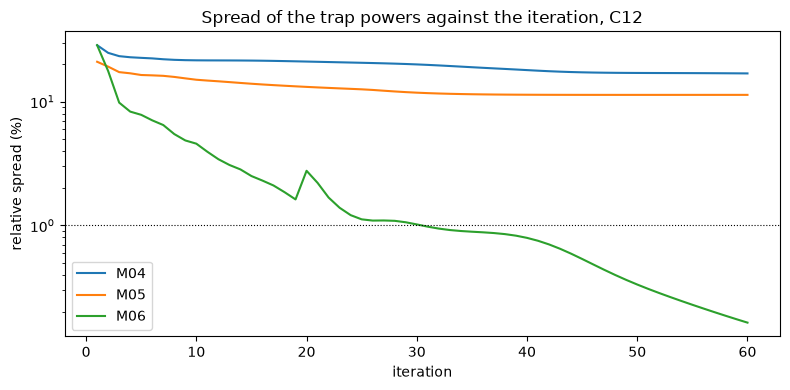

In [9]:
# the relative spread against the iteration for the three methods, on a log axis
fig, ax = plt.subplots(figsize=(8, 4))
for name, res in runs.items():
    ax.semilogy([h["iteration"] for h in res.history], [h["rel_std"] for h in res.history], label=name)
ax.axhline(1.0, color="k", lw=0.8, ls=":")
ax.set_xlabel("iteration")
ax.set_ylabel("relative spread (%)")
ax.set_title("Spread of the trap powers against the iteration, C12")
ax.legend()
fig.tight_layout()
plt.show()

Plain Gerchberg-Saxton decays from 28.55 to 21.55 percent in ten iterations and then barely moves, 19.97 at iteration 30 and 16.89 at 60. The adaptive additive curve lies below it all along, at 11.81 percent at iteration 30 and 11.34 at 60, and also flattens. Weighted Gerchberg-Saxton starts exactly where plain Gerchberg-Saxton does, at 28.55 percent after one iteration, because its first projection uses the initial weights unchanged, and then falls steeply: 4.57 percent at iteration 10, 1.02 at 30 and 0.16 at 60, and it is the only curve that crosses the dotted line. The curve is not monotone: near iteration 20 it jumps from about 1.6 to about 2.7 percent and lingers just above 1 percent from iteration 25 to 30 before it crosses the line and keeps falling, so a weighted loop can lose ground for a few iterations on its way down. The figure does not show how the weights themselves evolve, and it does not tell what they cost, which the efficiencies of the previous cell and the next figure do.

The second figure has two panels. On the left, the weight of the first update against the trap power at the start. On the right, the uniformity and the efficiency after 30 iterations against $\alpha$.

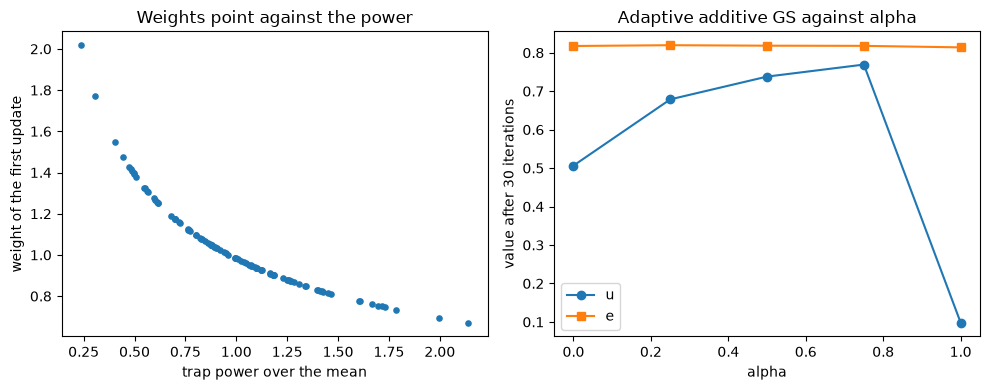

In [10]:
# left: the weight of the first update against the trap power at the start; right: the alpha sweep
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.scatter(power0 / power0.mean(), w1, s=14)
ax1.set_xlabel("trap power over the mean")
ax1.set_ylabel("weight of the first update")
ax1.set_title("Weights point against the power")
alphas = sorted(sweep)
ax2.plot(alphas, [sweep[a]["uniformity"] for a in alphas], "o-", label="u")
ax2.plot(alphas, [sweep[a]["efficiency"] for a in alphas], "s-", label="e")
ax2.set_xlabel("alpha")
ax2.set_ylabel("value after 30 iterations")
ax2.set_title("Adaptive additive GS against alpha")
ax2.legend()
fig.tight_layout()
plt.show()

On the left the weights fall as the power rises, from 2.018 for the dimmest traps to 0.671 for the brightest, and the points lie on one smooth decreasing curve, the inverse square root of the power, which the straight-line correlation of minus 0.914 in the first cell describes only roughly. That is the whole mechanism: ask for more where it came out low. On the right the uniformity rises from 0.5064 at $\alpha = 0$ to 0.7691 at $\alpha = 0.75$ while the efficiency stays between 0.8174 and 0.8195, so a moderate adaptive term is free, but at $\alpha = 1$ the uniformity collapses to 0.0982 with a spread of 62.53 percent: with no amplitude term left, the request of a trap is the inverse of its own amplitude, which I read as an overshoot, though this notebook does not test that reading. The bracket as printed, with the amplitudes in absolute units, reaches a uniformity of 0.5913, better than plain Gerchberg-Saxton and worse than the scaled version at 0.7379, which is why the product normalizes.

## Results

**Answer:** Weights turn Gerchberg-Saxton into a uniform array by asking each trap for more when it came out dim and for less when it came out bright. On C12 the weights of the first update run from 0.671 to 2.018 and have a correlation of minus 0.914 with the trap power. With them the relative spread falls to 4.57 percent at iteration 10 and 1.02 percent at iteration 30, against 21.55 and 19.97 percent for plain Gerchberg-Saxton and 15.02 and 11.81 percent for the adaptive additive variant. On the case seed weighted Gerchberg-Saxton needs 9 iterations to get under 5 percent, 18 to get under 2 and 31 to get under 1, and from three other seeds 8 to 10, 19 to 25 and 23 to 31, so the speed depends on the random start but the order of magnitude does not. The uniformity is 0.9705 against 0.5064 and 0.7379, at a cost of 0.0125 in efficiency (0.8049 against 0.8174). The adaptive term is free up to $\alpha = 0.75$ and breaks at $\alpha = 1$, where the uniformity is 0.0982.

## Summary

A weight per trap with memory is what makes Gerchberg-Saxton uniform. It costs about one hundredth of the efficiency on this array, takes from 8 iterations (to 5 percent) to 31 (to 1 percent) to reach the spread an experiment asks for, depending on the start, and it does not need anything but the trap fields that the iteration already computes. The adaptive additive variant is the cheap middle way: it improves the uniformity at no cost in efficiency and never reaches the weighted result. The next notebook asks whether the product's phase-fixed variant of the weights keeps up with the state of the art on an array of a thousand traps.

## References

- Di Leonardo, Ianni and Ruocco, "Computer generation of optimal holograms for optical trap arrays", Optics Express 15, 1913 (2007), https://doi.org/10.1364/OE.15.001913.